# ***Projet 2 - Analysez les données de systèmes éducatifs :***


---



## **EXERCICE 1 :**



#Analysez des données de systèmes éducatifs

Objectif : Transformer des données brutes hétérogènes en un score d'attractivité exploitable pour la prise de décision stratégique.

Approche : architecturale modulaire

# Étape 1 : Configuration et Initialisation de l'Environnement

**Explication :**

Avant toute manipulation, nous définissons les paramètres globaux du projet. Contrairement à une approche "scripting", nous isolons la configuration (chemins, constantes, poids) du code logique. Cela garantit la maintenabilité et la reproductibilité du code.

**Points clés :**

Indépendance de l'environnement : Suppression des dépendances colab au profit de chemins relatifs standards.

Centralisation des règles métier : Les indicateurs et leurs poids sont définis en constantes (CONFIG) pour être modifiés facilement sans toucher au code.

In [1]:
# ==============================================================================
# 1. INITIALISATION DE L'ENVIRONNEMENT & DÉPENDANCES
# ==============================================================================
import os
import sys

# Détection de l'environnement (Google Colab ou Local)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Configuration automatique de Poetry si nous sommes sur Colab
# Cela permet de garantir que le fichier de configuration standard (pyproject.toml) est présent
if IN_COLAB:
    # Installation silencieuse de Poetry si absent
    if os.system("poetry --version") != 0:
        print("Installation de Poetry en cours...")
        os.system("pip install -q poetry")

    # Configuration pour créer le .venv dans le dossier projet
    os.system("poetry config virtualenvs.in-project true")

    # Initialisation du projet si le fichier de conf n'existe pas encore
    if not os.path.exists("pyproject.toml"):
        print("Génération du fichier de configuration (pyproject.toml)...")
        # Création du fichier avec les dépendances du projet
        os.system('poetry init --name "projet-2-education" '
                  '--description "Analyse des données éducatives mondiales" '
                  '--author "Data Engineer <student@openclassrooms.com>" '
                  '--dependency pandas --dependency numpy '
                  '--dependency matplotlib --dependency seaborn '
                  '--dependency openpyxl --no-interaction')

        # Installation / Résolution des dépendances
        os.system("poetry install")
        print("Environnement virtuel configuré avec succès.")
    else:
        print("Fichier pyproject.toml détecté. Environnement déjà configuré.")

# ==============================================================================
# 2. IMPORTS DES LIBRAIRIES
# ==============================================================================

# Bibliothèques tierces
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 3. MONTAGE DU STORAGE (GOOGLE DRIVE)
# ==============================================================================
if IN_COLAB:
    mount_path = '/content/drive'
    if not os.path.exists(mount_path):
        print(f"Montage du volume distant vers {mount_path}...")
        drive.mount(mount_path)
    else:
        pass # Le drive est déjà monté

# ==============================================================================
# 4. CONFIGURATION GLOBALE (CONSTANTES)
# ==============================================================================

# Chemin racine (Point de montage)
BASE_PATH = "/content/drive/MyDrive/data/"

CONFIG = {
    # Chemins relatifs vers les sources de données
    "PATHS": {
        "DATA": os.path.join(BASE_PATH, "EdStatsData.csv"),
        "METADATA": os.path.join(BASE_PATH, "EdStatsCountry.csv"),
        "SERIES": os.path.join(BASE_PATH, "EdStatsSeries.csv"),
        "FOOTNOTE": os.path.join(BASE_PATH, "EdStatsFootNote.csv")
    },

    # Indicateurs retenus pour le scoring
    "INDICATORS": [
        'IT.NET.USER.P2',
        'SP.POP.0014.TO.ZS',
        'NY.GDP.PCAP.PP.CD',
        'SE.SEC.ENRL'
    ],

    # Mapping pour l'affichage (Codes -> Labels FR)
    "LABELS": {
        'IT.NET.USER.P2': 'Internet (%)',
        'SP.POP.0014.TO.ZS': 'Jeunesse (<14ans %)',
        'NY.GDP.PCAP.PP.CD': 'Richesse (PIB/hab $)',
        'SE.SEC.ENRL': 'Volume Élèves (Sec.)'
    },

    # Pondération métier pour le calcul du score
    "WEIGHTS": {
        'IT.NET.USER.P2': 0.3,
        'SP.POP.0014.TO.ZS': 0.3,
        'NY.GDP.PCAP.PP.CD': 0.2,
        'SE.SEC.ENRL': 0.2
    },

    # Fenêtre temporelle d'analyse
    "YEAR_RANGE": [2010, 2020]
}

print(f"Pipeline initialisé. Chargement des données depuis : {BASE_PATH}")

Installation de Poetry en cours...
Génération du fichier de configuration (pyproject.toml)...
Environnement virtuel configuré avec succès.
Pipeline initialisé. Chargement des données depuis : /content/drive/MyDrive/data/


In [20]:
# ==============================================================================
# 5. TEST UNITAIRE : VALIDATION DE L'ENVIRONNEMENT VIRTUEL (SANDBOX)
# ==============================================================================
import subprocess

# Création du script de test
test_script = """
import sys
import pandas as pd
print(f"   [OK] Interpréteur python : {sys.executable}")
print(f"   [OK] Pandas version : {pd.__version__}")
print("   [SUCCESS] L'environnement virtuel est fonctionnel.")
"""

with open("env_check.py", "w") as f:
    f.write(test_script)

print("Lancement du test de l'environnement virtuel...")
print("-" * 50)

# Exécution via subprocess pour capturer l'affichage
try:
    result = subprocess.run(
        ["poetry", "run", "python", "env_check.py"],
        capture_output=True,
        text=True,
        check=True
    )
    # Affiche la sortie standard du script (les print)
    print(result.stdout)
    print("✅ VALIDATION RÉUSSIE : Code de sortie 0")

except subprocess.CalledProcessError as e:
    # En cas d'erreur
    print("❌ ÉCHEC DU TEST")
    print(e.stderr)

Lancement du test de l'environnement virtuel...
--------------------------------------------------
   [OK] Interpréteur python : /content/.venv/bin/python
   [OK] Pandas version : 2.3.3
   [SUCCESS] L'environnement virtuel est fonctionnel.

✅ VALIDATION RÉUSSIE : Code de sortie 0


# Étape 2 : Création des Outils d'Audit (Automatisation)

** Explication :**

Avant d'ingérer les données dans notre pipeline de scoring, nous devons qualifier l'ensemble des fichiers disponibles dans notre "Data Lake". Cette étape est capitale pour valider la qualité des données et éviter le principe du "Garbage In, Garbage Out".

J'ai conçu cette étape à la maniére d'un Middleware de validation : aucune donnée ne doit passer à l'étape suivante sans avoir été apprécié.

Détail technique de la fonction audit_exploratory :

Nous avons standardisé l'audit autour de 3 axes :

1. Définition de la Granularité & Unicité (La "Primary Key")

Objectif : Vérifier ce que représente une ligne (une transaction ? un utilisateur ? un agrégat ?) et supprimer les doublons stricts.

Analogie Dev : C'est l'équivalent d'une contrainte UNIQUE en SQL ou de la vérification de l'existence d'un utilisateur avant une inscription (User.exists()). Si nous avons des doublons, nos calculs de moyenne seront faussés.

2. Qualité de la Donnée (Null Safety)

Calcul de la densité : Nous calculons le taux de remplissage de chaque colonne.

Visualisation (Heatmap) : Génération d'une carte thermique (jaune/violet) pour repérer visuellement les "trous" dans le dataset (ex: une décennie entière manquante). C'est notre outil de diagnostic visuel immédiat.

Nettoyage automatique : Le script supprime proactivement les colonnes 100% vides (dropna(how='all')) pour alléger la mémoire.

Analogie Dev : C'est comme la validation des champs d'un formulaire (Frontend). Si un champ obligatoire est undefined ou null pour tout le monde, on retire l'input du DOM.

3. Profiling Statistique (Type Checking & Distribution)

Variables Numériques : Appel de describe() pour voir les écarts-types et les quartiles (détection d'outliers, ex: un âge négatif).

Variables Catégorielles : Analyse des fréquences (value_counts()) pour comprendre la répartition des labels (ex: combien de pays vs combien de régions).

Analogie Dev : C'est du "Unit Testing" sur la donnée. On vérifie que les types reçus (Int, Float, String) correspondent aux types attendus par nos fonctions de calcul.

In [3]:
def audit_exploratory(df, name="Dataset"):
    """
    - Dimensions et définition de la ligne.
    - Détection et suppression des doublons.
    - Analyse des valeurs manquantes (Calcul % + Visualisation Heatmap + Nettoyage).
    - Statistiques descriptives (Numérique) et Fréquences (Catégoriel).
    """
    print(f"\n{'='*10} AUDIT : {name} {'='*10}")
    # 1. Dimensions et Granularité
    n_rows, n_cols = df.shape
    print(f"1. Dimensions avant nettoyage : {n_rows} lignes x {n_cols} colonnes")
    # 2. Gestion des Doublons
    n_duplicates = df.duplicated().sum()
    if n_duplicates > 0:
        print(f"2. Doublons : {n_duplicates} détectés -> Suppression effectuée.")
        df = df.drop_duplicates()
    else:
        print(f"2. Doublons : Aucun doublon strict.")
    # 3. Valeurs Manquantes (Analyse & Visu)
    print("3. Analyse des Valeurs Manquantes :")
    # A. Visualisation Graphique (Heatmap)
    # On affiche un petit graphique pour voir où sont les trous (Jaune = Manquant)
    plt.figure(figsize=(10, 4))
    sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
    plt.title(f"Carte des Valeurs Manquantes : {name}")
    plt.xlabel("Colonnes")
    plt.ylabel("Lignes")
    plt.show()
    # B. Calcul de la proportion (Consigne stricte)
    missing_ratio = df.isna().mean().sort_values(ascending=False)
    print(" -> Proportion de valeurs manquantes (Top 10 pires colonnes) :")
    print(missing_ratio.head(10).apply(lambda x: f"{x:.2%}").to_string())
    # C. Nettoyage (Suppression des colonnes 100% vides)
    empty_cols = df.columns[df.isna().all()].tolist()
    if empty_cols:
        print(f" -> Nettoyage : {len(empty_cols)} colonnes entièrement vides supprimées.")
        df = df.dropna(axis=1, how='all')
    else:
        print(" -> Nettoyage : Aucune colonne entièrement vide.")
    print(f" -> Dimensions actuelles : {df.shape}")
    # 4. Statistiques Descriptives & Distributions
    print("4. Analyse des Types et Distributions :")
    # A. Colonnes Numériques
    num_cols = df.select_dtypes(include=[np.number]).columns
    if len(num_cols) > 0:
        print(f" - {len(num_cols)} Variables Numériques.")
        print(f" Aperçu statistiques (describe - Top 5) :\n{df[num_cols].describe().T.head(5).to_string()}")
    # B. Colonnes Catégorielles (Object)
    cat_cols = df.select_dtypes(include=['object']).columns
    if len(cat_cols) > 0:
        print(f" - {len(cat_cols)} Variables Catégorielles.")
        for col in cat_cols[:5]: # On limite l'affichage aux 5 premières pour ne pas saturer
            unique_count = df[col].nunique()
            print(f" > Distribution de '{col}' ({unique_count} uniques) - Top 3 :")
            print(f"{df[col].value_counts().head(3).to_string()}\n")
    return df # On retourne le dataframe nettoyé

### **Analyse Sémantique des Fichiers**
Suite à l'audit exploratoire automatique ci-dessus, voici la définition de la granularité pour les fichiers principaux:
* **EdStatsData.csv (Table de Faits)** :
    * **Une ligne représente :** La valeur d'un indicateur éducatif spécifique, pour un pays donné, à une date donnée (bien que le format soit ici "Wide" avec des colonnes par année).
    * **Structure :** Clé composite (Country Code, Indicator Code).
* **EdStatsCountry.csv (Table de Dimension)** :
    * **Une ligne représente :** Un pays, une région géographique ou un agrégat économique.
    * **Utilité :** Contient les métadonnées (Région, Groupe de revenus) permettant de filtrer les agrégats "Monde" ou "Région".
* **EdStatsSeries.csv (Table de Dimension)** :
    * **Une ligne représente :** La définition complète d'un indicateur (Code, Nom, Description longue).
* **EdStatsFootNote.csv** :
    * **Une ligne représente :** Une note de bas de page (méta-information) associée à une donnée spécifique (couple Pays/Date).
**Actions correctives appliquées :**
1. **Doublons :** Suppression automatique si détectés.
2. **Colonnes Inutilisables :** Les colonnes ne contenant aucune donnée (100% de NaN), souvent présentes en fin de fichier CSV mal formaté, ont été supprimées programmatiquement.

#Étape 3 : Chargement & Analyse Sémantique
**Objectif** : Charger les jeux de données principaux et valider leur structure (Granularité) avant tout croisement.
**Analyse Sémantique :**
* Fichier EdStatsData.csv (Table de Faits) :
  * Une ligne représente : La valeur d'un indicateur éducatif unique, pour un pays (ou région) donné.
  * Structure : C'est une combinaison composite (Clé Pays + Clé Indicateur).
  * Format : Les données sont en format "Large" (Wide), avec une colonne par année.
* Fichier EdStatsCountry.csv (Table de Dimension) :
  * Une ligne représente : Une entité géographique unique (Pays souverain, Région ou Agrégat économique).
  * Utilité : Contient les métadonnées (Région, Groupe de revenus) permettant de filtrer les agrégats "Monde" ou "Région" plus tard.

--- Étape 3 : Ingestion des Données ---
Chargement de : EdStatsData.csv
Chargement de : EdStatsCountry.csv

========== AUDIT : EdStatsData (Faits) ==========
1. Dimensions avant nettoyage : 886930 lignes x 70 colonnes
2. Doublons : Aucun doublon strict.
3. Analyse des Valeurs Manquantes :


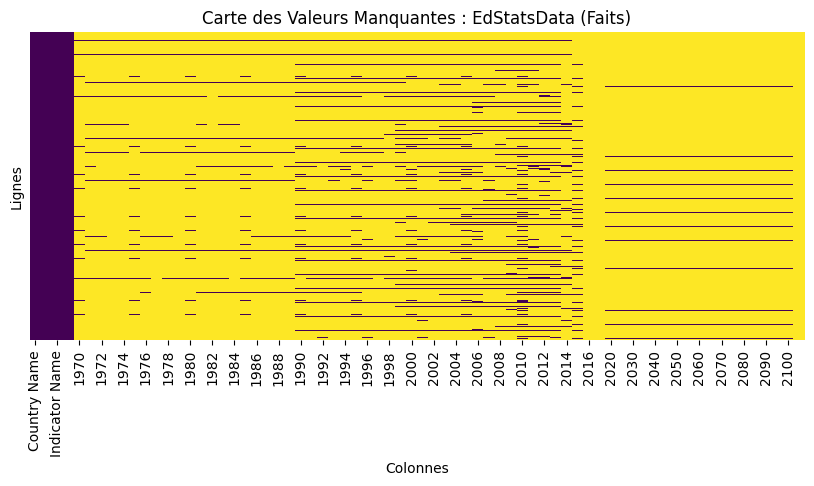

 -> Proportion de valeurs manquantes (Top 10 pires colonnes) :
Unnamed: 69    100.00%
2017            99.98%
2016            98.14%
1971            95.99%
1973            95.99%
1972            95.98%
1974            95.97%
1979            95.85%
1976            95.77%
1982            95.77%
 -> Nettoyage : 1 colonnes entièrement vides supprimées.
 -> Dimensions actuelles : (886930, 69)
4. Analyse des Types et Distributions :
 - 65 Variables Numériques.
 Aperçu statistiques (describe - Top 5) :
        count          mean           std       min       25%        50%         75%           max
1970  72288.0  1.974772e+09  1.211687e+11 -1.435564  0.890000   6.317724     62.5125  1.903929e+13
1971  35537.0  4.253638e+09  1.804814e+11 -1.594625  8.853210  63.162399  56552.0000  1.986457e+13
1972  35619.0  4.592365e+09  1.914083e+11 -3.056522  9.240920  66.551392  58636.5000  2.100916e+13
1973  35545.0  5.105006e+09  2.059170e+11 -4.032582  9.595200  69.695953  62029.0000  2.238367e+13
1974 

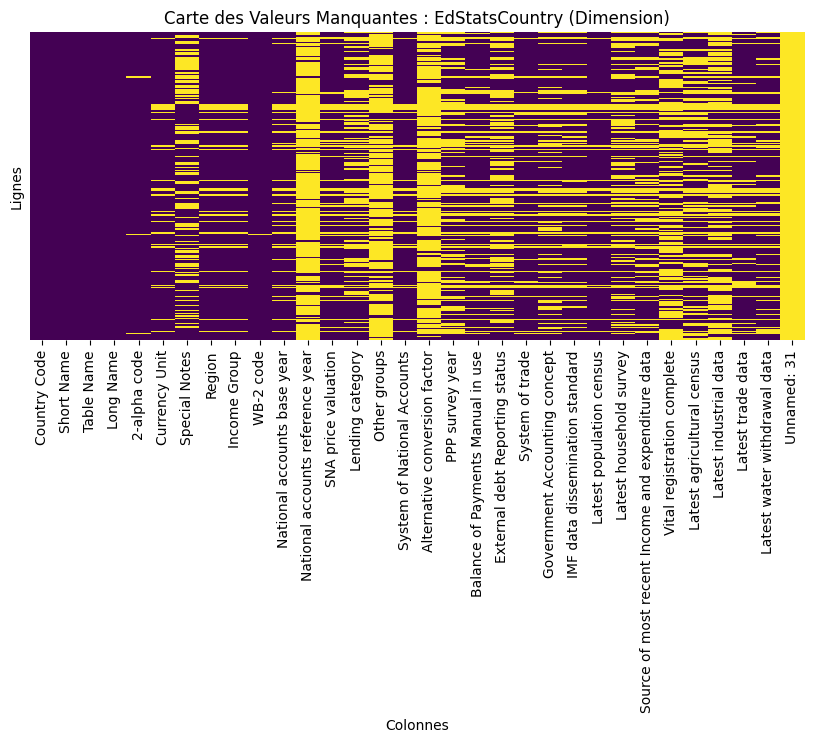

 -> Proportion de valeurs manquantes (Top 10 pires colonnes) :
Unnamed: 31                         100.00%
National accounts reference year     86.72%
Alternative conversion factor        80.50%
Other groups                         75.93%
Latest industrial data               55.60%
Vital registration complete          53.94%
External debt Reporting status       48.55%
Latest household survey              41.49%
Latest agricultural census           41.08%
Lending category                     40.25%
 -> Nettoyage : 1 colonnes entièrement vides supprimées.
 -> Dimensions actuelles : (241, 31)
4. Analyse des Types et Distributions :
 - 3 Variables Numériques.
 Aperçu statistiques (describe - Top 5) :
                                  count         mean       std     min      25%     50%     75%     max
National accounts reference year   32.0  2001.531250  5.248560  1987.0  1996.75  2002.0  2005.0  2012.0
Latest industrial data            107.0  2008.102804  2.616834  2000.0  2007.50  2009.

In [4]:
def load_data(path):
    """Charge un fichier CSV"""
    if os.path.exists(path):
        print(f"Chargement de : {os.path.basename(path)}")
        return pd.read_csv(path)
    else:
        print(f"Erreur : Fichier introuvable à {path}")
        return None

print(f"--- Étape 3 : Ingestion des Données ---")
# 1. Chargement des datasets
df_data = load_data(CONFIG["PATHS"]["DATA"])
df_country = load_data(CONFIG["PATHS"]["METADATA"])
# 2. Validation immédiate via notre outil d'audit
if df_data is not None and df_country is not None:
    # Audit du fichier principal (Données)
    # On utilise bien 'audit_exploratory' définie à l'étape 2
    audit_exploratory(df_data, "EdStatsData (Faits)")
    # Audit du fichier de métadonnées (Pays)
    audit_exploratory(df_country, "EdStatsCountry (Dimension)")
    print("\nÉtape 3 : Ingestion et audit initial terminés")
else:
    print("Étape 3 : ÉCHEC. Vérifiez les chemins dans CONFIG.")

#Étape 4 : Nettoyage & Filtrage (Règles Métier)
**Objectif :** Isoler les données pertinentes pour ne garder que les pays souverains et les indicateurs choisis.
**Règles de Gestion Appliquées :**
1. Exclusion des Agrégats Macro-économiques :
  * Dans le fichier EdStatsCountry, les lignes correspondant à des régions (ex: "World", "Euro area") ont une colonne Region vide (NaN).
  * Action : Nous ne conservons que les lignes où Region est renseignée.
2. Restriction aux Indicateurs Cibles :
  * Pour éviter de manipuler un DataFrame de plusieurs millions de lignes inutilement, nous filtrons immédiatement sur la liste CONFIG["INDICATORS"].

In [5]:
print(f"--- Étape 4 : Nettoyage & Filtrage ---")
# 1. Identification des Pays Valides (vs Agrégats)
# Règle : Si la 'Region' est NaN, c'est un agrégat (ex: World, Arab World) -> On supprime.
df_valid_countries = df_country.dropna(subset=['Region']).copy()
valid_country_codes = df_valid_countries['Country Code'].unique()
print(f"1. Filtrage des Entités Géographiques :")
print(f" - Total entités dans le fichier : {len(df_country)}")
print(f" - Pays souverains conservés : {len(valid_country_codes)}")
print(f" - Agrégats supprimés : {len(df_country) - len(valid_country_codes)}")
# 2. Application du filtre Pays sur la Data (Table de Faits)
# On ne garde que les lignes dont le Country Code est dans notre liste validée
rows_before = len(df_data)
df_clean = df_data[df_data['Country Code'].isin(valid_country_codes)].copy()
rows_after_country = len(df_clean)
print(f"2. Filtrage de la Table de Faits (Pays) :")
print(f" - Lignes avant : {rows_before}")
print(f" - Lignes après suppression des agrégats : {rows_after_country}")
# 3. Application du filtre Indicateurs
# On ne garde que les indicateurs définis dans la CONFIG
df_clean = df_clean[df_clean['Indicator Code'].isin(CONFIG["INDICATORS"])].copy()
rows_final = len(df_clean)
print(f"3. Filtrage des Indicateurs (Sélection : {len(CONFIG['INDICATORS'])} indicateurs) :")
print(f" - Lignes restantes pour l'analyse : {rows_final}")
# Petit check de sécurité
if df_clean.empty:
    print("ALERTE : Le DataFrame est vide après filtrage ! Vérifiez les codes indicateurs dans CONFIG.")
else:
    print(f"Nettoyage terminé. Prêt pour la transformation (Pivot).")

--- Étape 4 : Nettoyage & Filtrage ---
1. Filtrage des Entités Géographiques :
 - Total entités dans le fichier : 241
 - Pays souverains conservés : 214
 - Agrégats supprimés : 27
2. Filtrage de la Table de Faits (Pays) :
 - Lignes avant : 886930
 - Lignes après suppression des agrégats : 784310
3. Filtrage des Indicateurs (Sélection : 4 indicateurs) :
 - Lignes restantes pour l'analyse : 856
Nettoyage terminé. Prêt pour la transformation (Pivot).


#Étape 5 : Transformation (Pivoting & Imputation)

**Objectif :** Structurer les données pour le Scoring (1 ligne = 1 Pays).

** Méthodologie :**

1. Agrégation Temporelle :

  * Les données contiennent une colonne par année (2010, 2011, etc.).

  * Pour simplifier la prise de décision, nous calculons une moyenne sur la période définie (ex: 2010-2020). Cela permet de lisser les variations annuelles et de combler les trous ponctuels.

2. Pivot (Transposition) :

  * Transformation du format "Long" (Indicateurs en lignes) vers un format "Wide" (Indicateurs en colonnes).

3. Nettoyage Final :

  * Suppression des pays qui n'ont pas de données pour tous les indicateurs clés (approche stricte pour garantir la qualité du score).

In [6]:
print(f"--- Étape 5 : Transformation & Pivot ---")

# 1. Sélection dynamique des colonnes Années
# On génère la liste théorique [2010, 2011, ... 2020]
target_years = [str(y) for y in range(CONFIG["YEAR_RANGE"][0], CONFIG["YEAR_RANGE"][1] + 1)]
# On ne garde que celles qui existent vraiment dans le CSV
available_years = [col for col in target_years if col in df_clean.columns]

print(f"1. Période d'analyse : {min(available_years)} à {max(available_years)}")

# 2. Calcul de la Moyenne (Agrégation)
# axis=1 signifie qu'on calcule la moyenne horizontalement (sur les années)
df_clean['Value_Mean'] = df_clean[available_years].mean(axis=1)

# 3. Pivot Table (La transformation clé)
# Index = Pays
# Colonnes = Codes Indicateurs
# Valeurs = Notre moyenne calculée
df_pivot = df_clean.pivot_table(
    index=['Country Name', 'Country Code'],
    columns='Indicator Code',
    values='Value_Mean'
)

print(f"2. Dimensions après Pivot : {df_pivot.shape}")

# 4. Gestion des Données Manquantes post-pivot
# Certains pays peuvent avoir le PIB mais pas les utilisateurs Internet.
# Pour le scoring, on veut des données complètes.
n_before_drop = len(df_pivot)
df_pivot = df_pivot.dropna() # Suppression des pays incomplets
n_after_drop = len(df_pivot)

print(f"3. Nettoyage des pays incomplets :")
print(f"   - Pays candidats initiaux : {n_before_drop}")
print(f"   - Pays qualifiés (données complètes sur tous les indicateurs) : {n_after_drop}")
print(f"   - Pays disqualifiés (manque au moins 1 indicateur) : {n_before_drop - n_after_drop}")

# Aperçu du résultat
print("\n Aperçu du DataFrame prêt pour le Scoring :")
print(df_pivot.head(3))

--- Étape 5 : Transformation & Pivot ---
1. Période d'analyse : 2010 à 2020
2. Dimensions après Pivot : (210, 4)
3. Nettoyage des pays incomplets :
   - Pays candidats initiaux : 210
   - Pays qualifiés (données complètes sur tous les indicateurs) : 163
   - Pays disqualifiés (manque au moins 1 indicateur) : 47

 Aperçu du DataFrame prêt pour le Scoring :
Indicator Code             IT.NET.USER.P2  NY.GDP.PCAP.PP.CD   SE.SEC.ENRL  \
Country Name Country Code                                                    
Afghanistan  AFG                 6.601467        1801.860450  2.418162e+06   
Albania      ALB                56.510334       10801.168395  3.425055e+05   
Algeria      DZA                25.535075       13801.403719  4.594370e+06   

Indicator Code             SP.POP.0014.TO.ZS  
Country Name Country Code                     
Afghanistan  AFG                   45.941882  
Albania      ALB                   19.779244  
Algeria      DZA                   28.032116  


**Méthode B :**

Filtrage par Jointure (Merge Inner)
Cette méthode permet d'ajouter des informations (comme la Région) au passage.

Elle ne garde que les correspondances exactes entre le fichier cible et notre table df_country_clean.

--- Étape 6 : Calcul du Score ---
1. Normalisation des indicateurs (0 -> 1) :
   - IT.NET.USER.P2 : Min=0.89, Max=96.51 -> Normalisé.
   - SP.POP.0014.TO.ZS : Min=11.36, Max=50.16 -> Normalisé.
   - NY.GDP.PCAP.PP.CD : Min=709.96, Max=127041.21 -> Normalisé.
   - SE.SEC.ENRL : Min=7412.17, Max=119824084.00 -> Normalisé.

2. Application des Pondérations :
   - IT.NET.USER.P2 (Poids: 0.3) ajouté au score.
   - SP.POP.0014.TO.ZS (Poids: 0.3) ajouté au score.
   - NY.GDP.PCAP.PP.CD (Poids: 0.2) ajouté au score.
   - SE.SEC.ENRL (Poids: 0.2) ajouté au score.

========== RÉSULTATS DU SCORING ==========
Meilleur candidat : ('Luxembourg', 'LUX')
Score : 0.4856 / 1.0

--- TOP 10 PAYS CIBLES ---
Indicator Code                  Total_Score  IT.NET.USER.P2  SP.POP.0014.TO.ZS  NY.GDP.PCAP.PP.CD   SE.SEC.ENRL
Country Name      Country Code                                                                                 
Luxembourg        LUX              0.485602       93.696330          16.925009   

/tmp/ipython-input-583688855.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10,


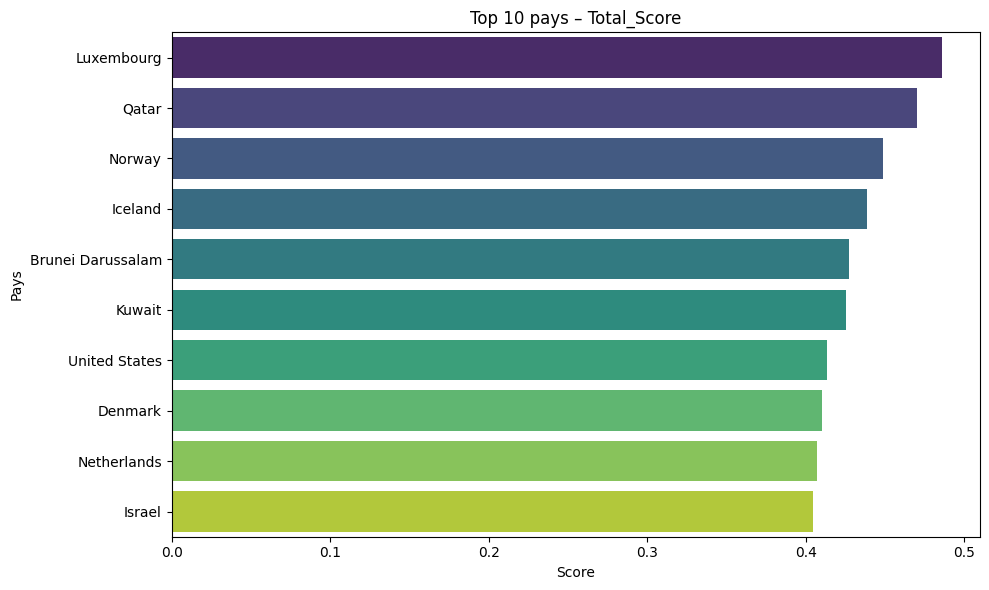

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print(f"--- Étape 6 : Calcul du Score ---")

# On travaille sur une copie pour ne pas altérer les données brutes
df_final = df_pivot.copy()
valid_indicators = []

print("1. Normalisation des indicateurs (0 -> 1) :")

for col in CONFIG["INDICATORS"]:
    # Vérification que la colonne existe bien dans le pivot
    if col in df_final.columns:
        valid_indicators.append(col)

        # Récupération Min et Max
        min_v = df_final[col].min()
        max_v = df_final[col].max()

        col_norm_name = f"{col}_norm"

        # Sécurité Division par Zéro (si max == min)
        if max_v != min_v:
            df_final[col_norm_name] = (df_final[col] - min_v) / (max_v - min_v)
        else:
            df_final[col_norm_name] = 0.0

        print(f"   - {col} : Min={min_v:.2f}, Max={max_v:.2f} -> Normalisé.")
    else:
        print(f"ATTENTION : L'indicateur {col} est absent du DataFrame pivoté.")

# 2. Calcul du Score Pondéré
print("\n2. Application des Pondérations :")
df_final['Total_Score'] = 0

for col in valid_indicators:
    # On récupère le poids depuis la CONFIG (défaut 0 si pas trouvé)
    weight = CONFIG["WEIGHTS"].get(col, 0)

    # On ajoute au score total : Valeur Normalisée * Poids
    df_final['Total_Score'] += df_final[f"{col}_norm"] * weight
    print(f"   - {col} (Poids: {weight}) ajouté au score.")

# 3. Tri final
df_final = df_final.sort_values(by='Total_Score', ascending=False)

# Affichage du PODIUM
print(f"\n{'='*10} RÉSULTATS DU SCORING {'='*10}")
print(f"Meilleur candidat : {df_final.index[0]}")
print(f"Score : {df_final.iloc[0]['Total_Score']:.4f} / 1.0")

# Affichage du Top 10 propre
display_cols = ['Total_Score'] + valid_indicators
print("\n--- TOP 10 PAYS CIBLES ---")
print(df_final[display_cols].head(10).to_string())

# Visualisation avec Seaborn
top10 = df_final.head(10).reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(data=top10,
            x='Total_Score',
            y=top10.columns[0],  # Nom de la colonne d'index (pays)
            palette="viridis")
plt.title("Top 10 pays – Total_Score")
plt.xlabel("Score")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()


#Étape 6 : Normalisation & Scoring Algorithmique

**Objectif :** Calculer un score unique d'attractivité pour chaque pays.

**Algorithme :**

1. **Normalisation (Min-Max Scaling) :**

  * Chaque indicateur est redimensionné sur une échelle de 0 à 1.
  
  * Formule : $Val_{norm} = \frac{Val - Min}{Max - Min}$
  
  * Cela permet de comparer équitablement des volumes (ex: Population) et des ratios (ex: % Internet).
  

2. **Pondération (Weighted Scoring) :**

  * Application des coefficients définis dans CONFIG["WEIGHTS"].

  * Formule : $Score = \sum (Val_{norm} \times Poids)$
  
  
3. **Classement (Ranking) :**

  * Tri décroissant pour identifier les marchés prioritaires.

In [8]:
print(f"--- Étape 6 : Calcul du Score ---")

# On travaille sur une copie pour ne pas altérer les données brutes
df_final = df_pivot.copy()
valid_indicators = []

print("1. Normalisation des indicateurs (0 -> 1) :")

for col in CONFIG["INDICATORS"]:
    # Vérification que la colonne existe bien dans le pivot
    if col in df_final.columns:
        valid_indicators.append(col)

        # Récupération Min et Max
        min_v = df_final[col].min()
        max_v = df_final[col].max()

        col_norm_name = f"{col}_norm"

        # Sécurité Division par Zéro (si max == min)
        if max_v != min_v:
            df_final[col_norm_name] = (df_final[col] - min_v) / (max_v - min_v)
        else:
            df_final[col_norm_name] = 0.0

        print(f"   - {col} : Min={min_v:.2f}, Max={max_v:.2f} -> Normalisé.")
    else:
        print(f"ATTENTION : L'indicateur {col} est absent du DataFrame pivoté.")

# 2. Calcul du Score Pondéré
print("\n2. Application des Pondérations :")
df_final['Total_Score'] = 0

for col in valid_indicators:
    # On récupère le poids depuis la CONFIG (défaut 0 si pas trouvé)
    weight = CONFIG["WEIGHTS"].get(col, 0)

    # On ajoute au score total : Valeur Normalisée * Poids
    df_final['Total_Score'] += df_final[f"{col}_norm"] * weight
    print(f"   - {col} (Poids: {weight}) ajouté au score.")

# 3. Tri final
df_final = df_final.sort_values(by='Total_Score', ascending=False)

# Affichage du PODIUM
print(f"\n{'='*10} RÉSULTATS DU SCORING {'='*10}")
print(f"Meilleur candidat : {df_final.index[0]}")
print(f"Score : {df_final.iloc[0]['Total_Score']:.4f} / 1.0")

# Affichage du Top 10 propre
display_cols = ['Total_Score'] + valid_indicators
print("\n--- TOP 10 PAYS CIBLES ---")
print(df_final[display_cols].head(10).to_string())

--- Étape 6 : Calcul du Score ---
1. Normalisation des indicateurs (0 -> 1) :
   - IT.NET.USER.P2 : Min=0.89, Max=96.51 -> Normalisé.
   - SP.POP.0014.TO.ZS : Min=11.36, Max=50.16 -> Normalisé.
   - NY.GDP.PCAP.PP.CD : Min=709.96, Max=127041.21 -> Normalisé.
   - SE.SEC.ENRL : Min=7412.17, Max=119824084.00 -> Normalisé.

2. Application des Pondérations :
   - IT.NET.USER.P2 (Poids: 0.3) ajouté au score.
   - SP.POP.0014.TO.ZS (Poids: 0.3) ajouté au score.
   - NY.GDP.PCAP.PP.CD (Poids: 0.2) ajouté au score.
   - SE.SEC.ENRL (Poids: 0.2) ajouté au score.

========== RÉSULTATS DU SCORING ==========
Meilleur candidat : ('Luxembourg', 'LUX')
Score : 0.4856 / 1.0

--- TOP 10 PAYS CIBLES ---
Indicator Code                  Total_Score  IT.NET.USER.P2  SP.POP.0014.TO.ZS  NY.GDP.PCAP.PP.CD   SE.SEC.ENRL
Country Name      Country Code                                                                                 
Luxembourg        LUX              0.485602       93.696330          16.925009   

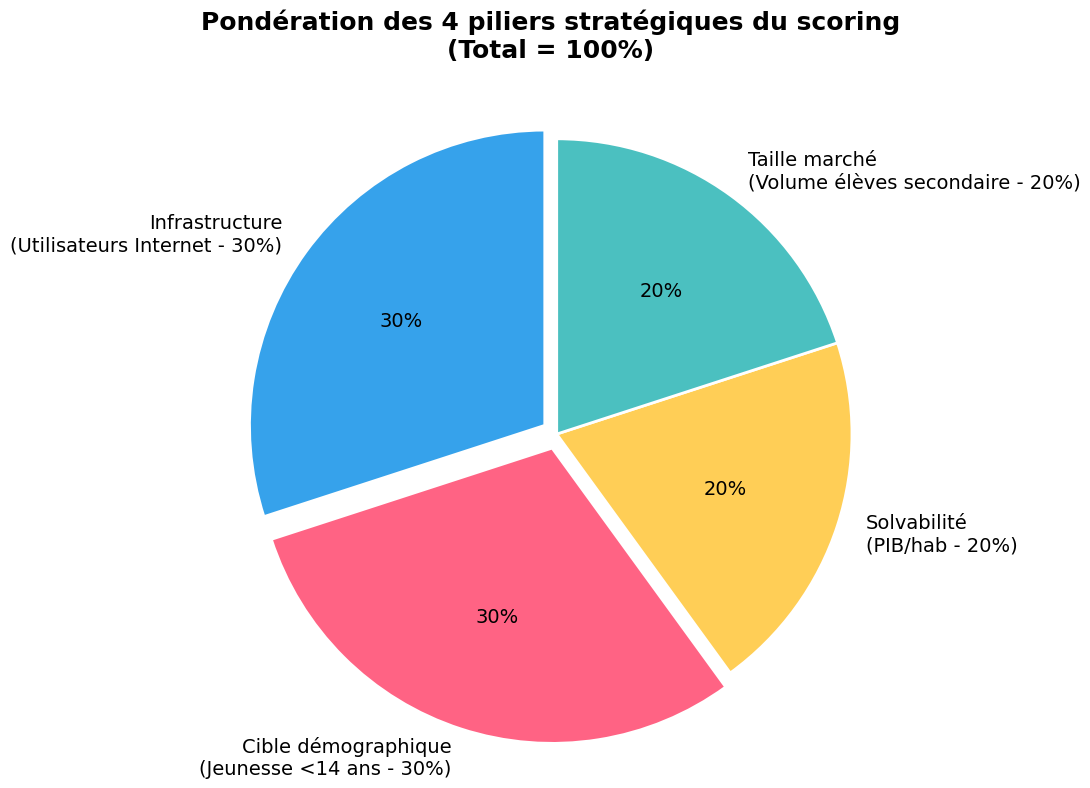

In [9]:
import matplotlib.pyplot as plt

# Données des pondérations
labels = [
    'Infrastructure\n(Utilisateurs Internet - 30%)',
    'Cible démographique\n(Jeunesse <14 ans - 30%)',
    'Solvabilité\n(PIB/hab - 20%)',
    'Taille marché\n(Volume élèves secondaire - 20%)'
]
sizes = [30, 30, 20, 20]
colors = ['#36A2EB', '#FF6384', '#FFCE56', '#4BC0C0']
explode = (0.05, 0.05, 0, 0)

# Création du camembert
plt.figure(figsize=(10, 8))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.0f%%', startangle=90, explode=explode,
        textprops={'fontsize': 14}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})

# Titre
plt.title('Pondération des 4 piliers stratégiques du scoring\n(Total = 100%)',
          fontsize=18, fontweight='bold', pad=30)

# Légende circulaire et égalisation des axes
plt.axis('equal')

# Affichage
plt.tight_layout()
plt.show()

#Étape 7 : Restitution & Export

**Objectif :** Sauvegarder les résultats pour l'analyse visuelle et le reporting.

**Actions :**

1. Export CSV : Nous sauvegardons le DataFrame scoré (df_final) dans un fichier standard.

2. Sélection : Le fichier contient les indicateurs normalisés, le score total, mais aussi les valeurs brutes (si conservées) pour permettre de créer des graphiques dans Tableau ou PowerBI.

In [10]:
from google.colab import files # Spécifique pour télécharger depuis Colab

print(f"--- Étape 7 : Export des Résultats ---")

# 1. Définition du nom du fichier de sortie
output_filename = "resultats_scoring_edtech_FR.csv"
output_path = os.path.join(BASE_PATH, output_filename)

# 2. Préparation du DataFrame pour l'export (Renommage des colonnes)
# On prend df_final et on applique le dictionnaire de traduction
df_export = df_final.rename(columns=CONFIG["LABELS"])

# 3. Sauvegarde sur le Drive
try:
    df_export.to_csv(output_path)
    print(f"Fichier sauvegardé sur le Drive : {output_path}")
except Exception as e:
    print(f"Erreur lors de la sauvegarde Drive : {e}")
    # Fallback sauvegarde locale
    df_export.to_csv(output_filename)
    print(f" -> Fichier sauvegardé localement (Session Colab) : {output_filename}")

# 4. Téléchargement automatique vers votre PC
try:
    print("⬇Préparation du téléchargement vers votre machine locale...")
    files.download(output_filename)
except Exception as e:
    print("Note : Le téléchargement automatique n'est disponible que sur Google Colab.")

print(f"\n{'='*30}")
print(f"EXERCICE 1 TERMINÉ")
print(f"{'='*30}")

--- Étape 7 : Export des Résultats ---
Fichier sauvegardé sur le Drive : /content/drive/MyDrive/data/resultats_scoring_edtech_FR.csv
⬇Préparation du téléchargement vers votre machine locale...
Note : Le téléchargement automatique n'est disponible que sur Google Colab.

EXERCICE 1 TERMINÉ


#5. Résultats & Interprétation

Le modèle met en avant des pays à fort revenu et infrastructure numérique mature.

**Top 3 Pays Identifiés :**

* Luxembourg (Score: 0.48) - Marché riche mais saturé.

* Qatar (Score: 0.47) - Fort investissement éducatif.

* Norvège (Score: 0.45) - Culture numérique avancée.

**Observation Stratégique :**

Les États-Unis (7ème) représentent le meilleur compromis entre un score élevé (0.41) et un volume de marché massif (24M élèves vs 44k pour le Luxembourg). Ils constituent probablement la cible prioritaire pour une expansion à grande échelle.

---

## **EXERCICE 2 :**

#Analyse Exploratoire Approfondie

Contexte : Nous avons identifié un "Top 10" des pays. Nous devons maintenant analyser la stabilité de ces indicateurs dans le temps et comprendre les corrélations.

Explication :

Dans l'exercice 1, nous avons calculé une moyenne pour le scoring.

Pour l'analyse visuelle (notamment l'évolution), nous avons besoin de revenir aux données temporelles (Time Series) que nous avions dans le DataFrame df_clean avant le pivot.

Nous allons filtrer ces données pour ne garder que notre Top 10 identifié précédemment.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphes
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("--- Initialisation ---")

# 1. Récupération du Top 10 (index du df_final de l'Ex 1)
top_countries_codes = df_final.head(10).index.get_level_values('Country Code')
print(f"Analyse focalisée sur les pays : {list(top_countries_codes)}")

# 2. Retour aux données temporelles (df_clean contient les années)
# On filtre df_clean pour ne garder que le Top 10
df_top_evolution = df_clean[df_clean['Country Code'].isin(top_countries_codes)].copy()

print(f" Données prêtes pour visualisation : {df_top_evolution.shape[0]} lignes.")

--- Initialisation ---
Analyse focalisée sur les pays : ['LUX', 'QAT', 'NOR', 'ISL', 'BRN', 'KWT', 'USA', 'DNK', 'NLD', 'ISR']
 Données prêtes pour visualisation : 40 lignes.


#Étape 1 : Analyse de la Distribution (Boxplots)

**Explication :**

Avant de regarder les tendances, il faut regarder la dispersion.
Les boîtes à moustaches (Boxplots) sont l'outil standard pour voir la médiane, l'écart type (la "largeur de la boîte"), les outliers (valeurs aberrantes).

Cela permet de voir si un pays est "stable" sur la période ou s'il a subi des changements importants.

--- Génération des graphiques (Traduits en Français) ---


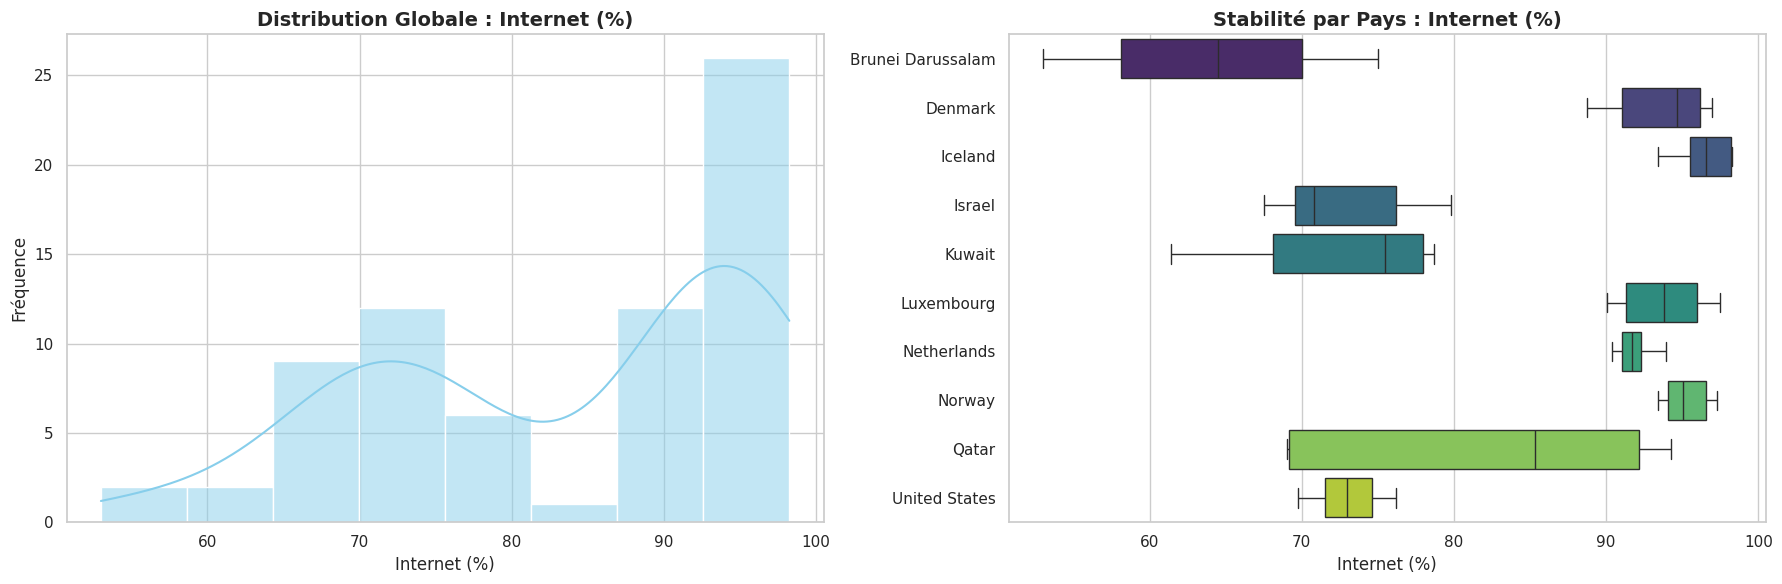

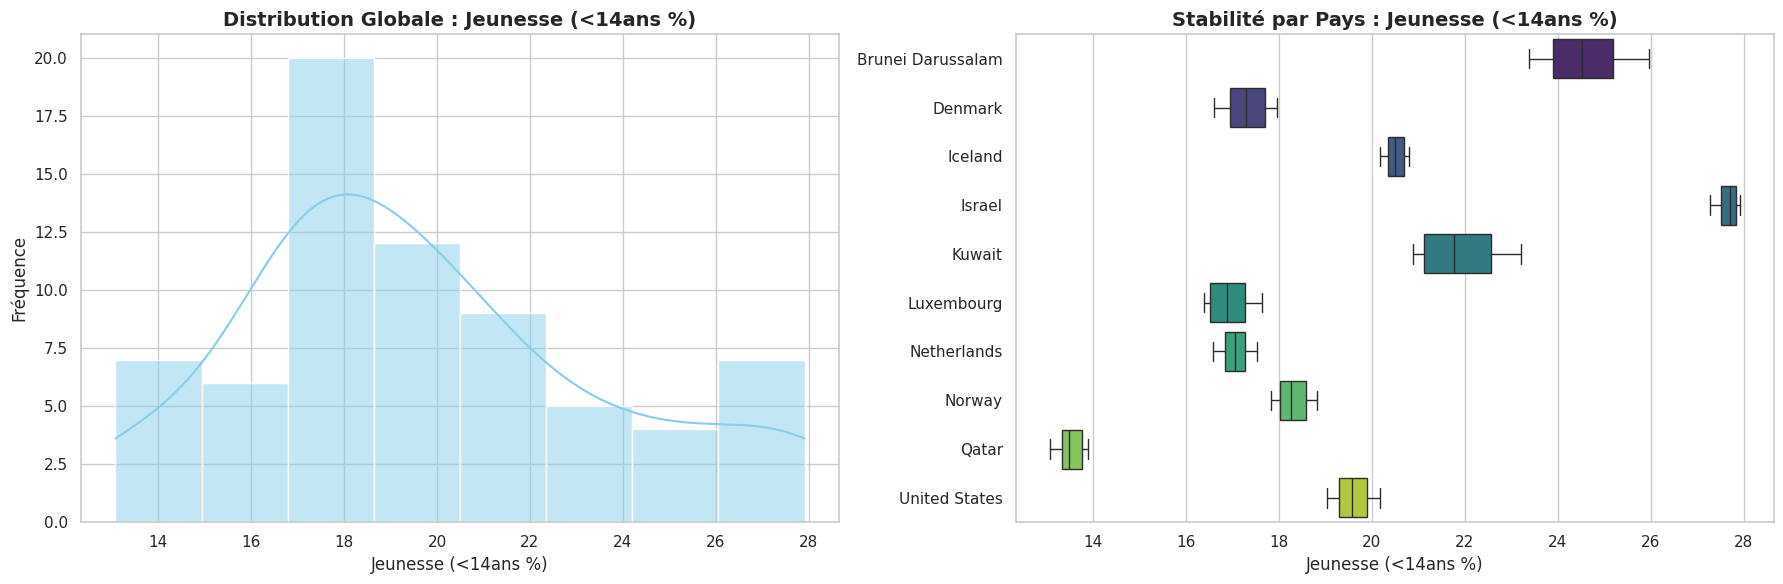

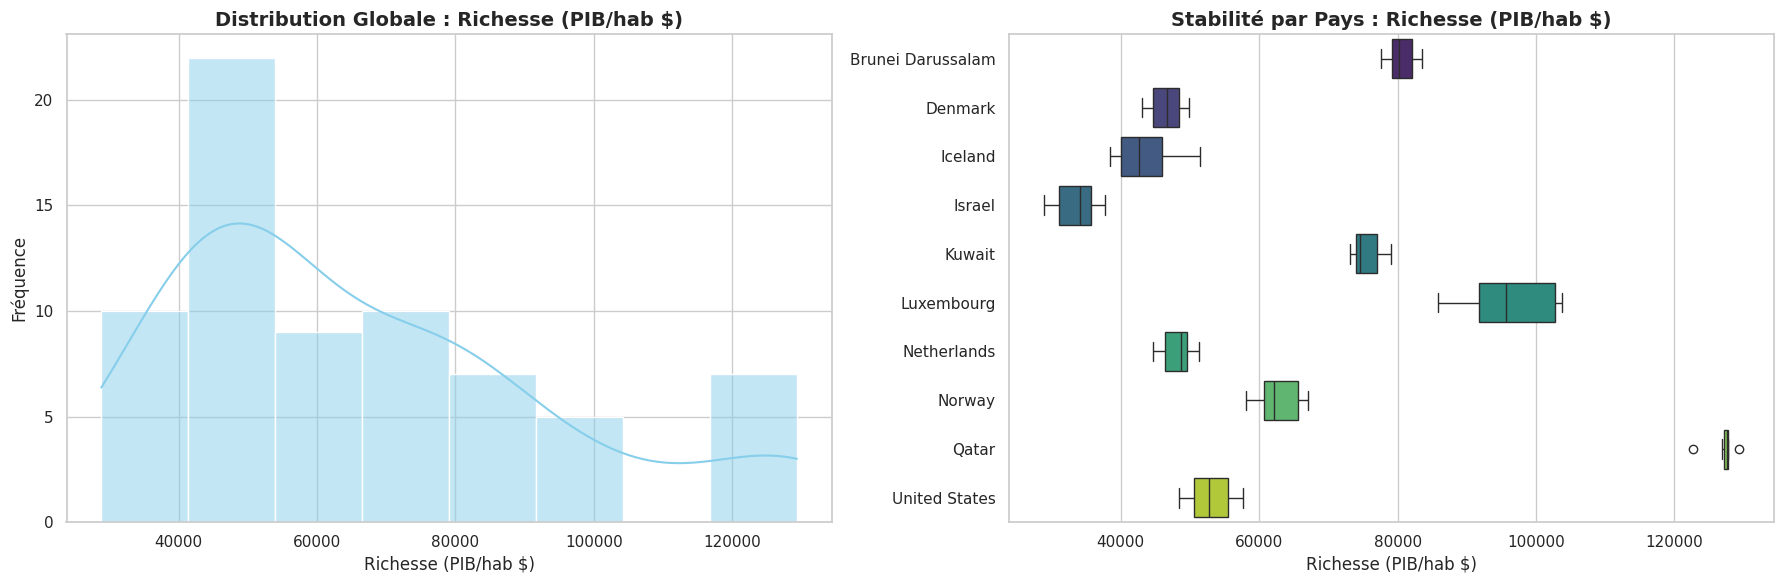

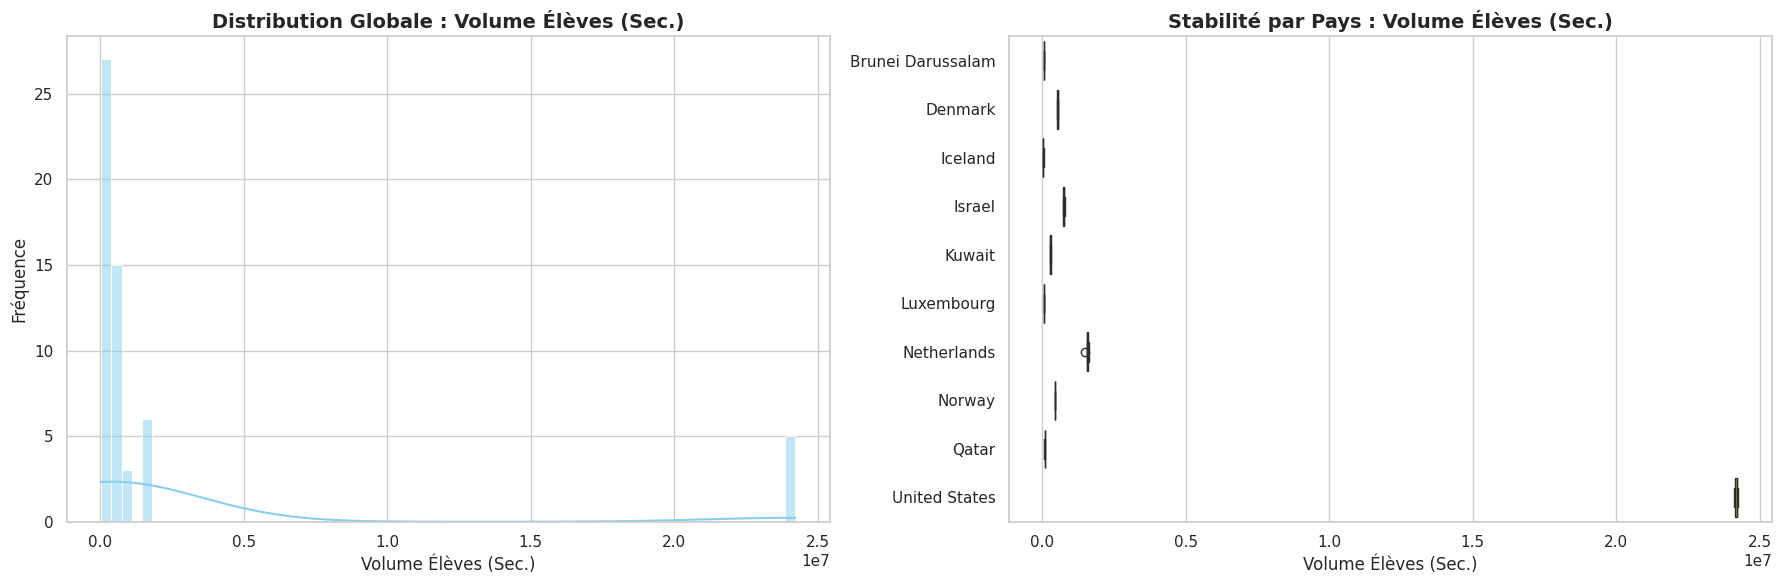

Étape 1 : Analyse des distribution terminée.


In [12]:
## Étape 1 : Visualisation des Distributions

import matplotlib.pyplot as plt
import seaborn as sns

def plot_distributions(df, indicators):
    """
    Affiche les graphiques avec titres et axes traduits.
    """
    # Transformation Seaborn
    years = [str(y) for y in range(CONFIG["YEAR_RANGE"][0], CONFIG["YEAR_RANGE"][1] + 1)
             if str(y) in df.columns]

    df_melt = df.melt(id_vars=['Country Name', 'Indicator Code'],
                      value_vars=years,
                      var_name='Année',
                      value_name='Valeur')

    for ind in indicators:
        # Récupération du nom français
        titre_fr = CONFIG["LABELS"].get(ind, ind)

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))
        subset = df_melt[df_melt['Indicator Code'] == ind]

        # Graphique 1 : Histogramme
        sns.histplot(data=subset, x="Valeur", kde=True, ax=axes[0], color="skyblue")
        axes[0].set_title(f"Distribution Globale : {titre_fr}", fontsize=14, fontweight='bold')
        axes[0].set_xlabel(titre_fr)
        axes[0].set_ylabel("Fréquence")

        # Graphique 2 : Boxplot par pays
        sns.boxplot(
            x='Valeur',
            y='Country Name',
            hue='Country Name',
            legend=False,
            data=subset,
            palette="viridis",
            ax=axes[1]
        )
        axes[1].set_title(f"Stabilité par Pays : {titre_fr}", fontsize=14, fontweight='bold')
        axes[1].set_xlabel(titre_fr)
        axes[1].set_ylabel("")

        plt.tight_layout()
        plt.show()

# Exécution avec les graphiques traduits
print("--- Génération des graphiques (Traduits en Français) ---")
# On récupère les codes des pays du Top 10 pour filtrer
top_countries_codes = df_final.head(10).index.get_level_values('Country Code')
df_top_evolution = df_clean[df_clean['Country Code'].isin(top_countries_codes)].copy()

plot_distributions(df_top_evolution, CONFIG["INDICATORS"])
print("Étape 1 : Analyse des distribution terminée.")

#Étape 2 : Analyse de l'Évolution Temporelle (Time Series)

**Explication :**

C'est le point pour répondre aux problématiques et statuer sur une solution (décision).

* La population scolaire augmente-t-elle ou baisse-t-elle ? (Marché d'avenir ou déclinant ?)
* L'accès Internet est-il en croissance rapide ?

Nous allons tracer des courbes d'évolution pour visualiser la dynamique de chaque pays.

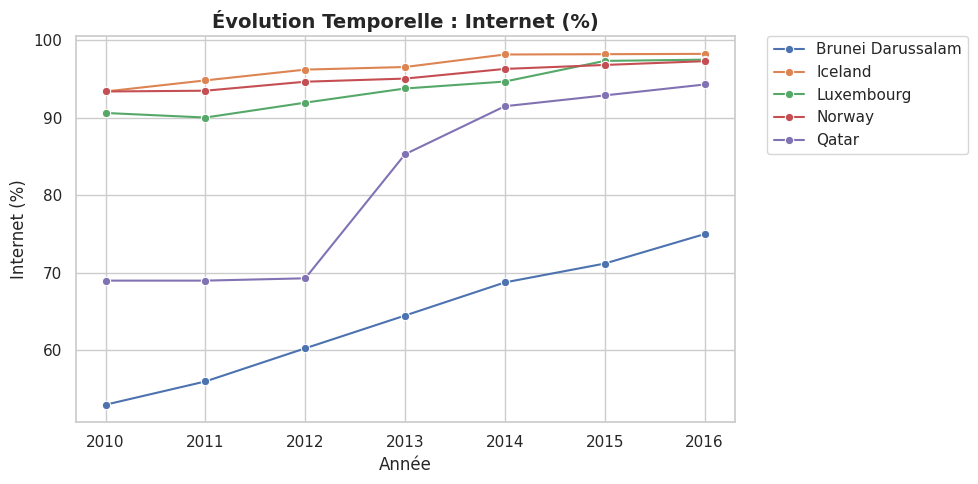

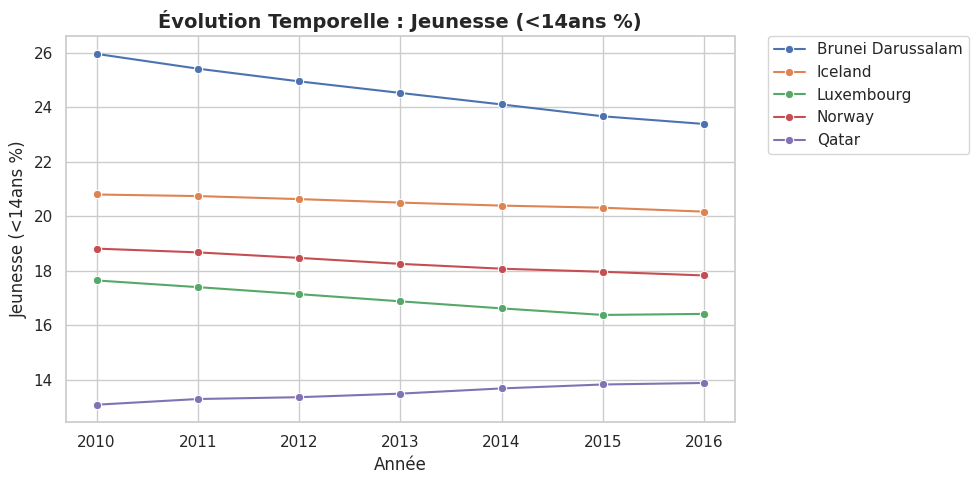

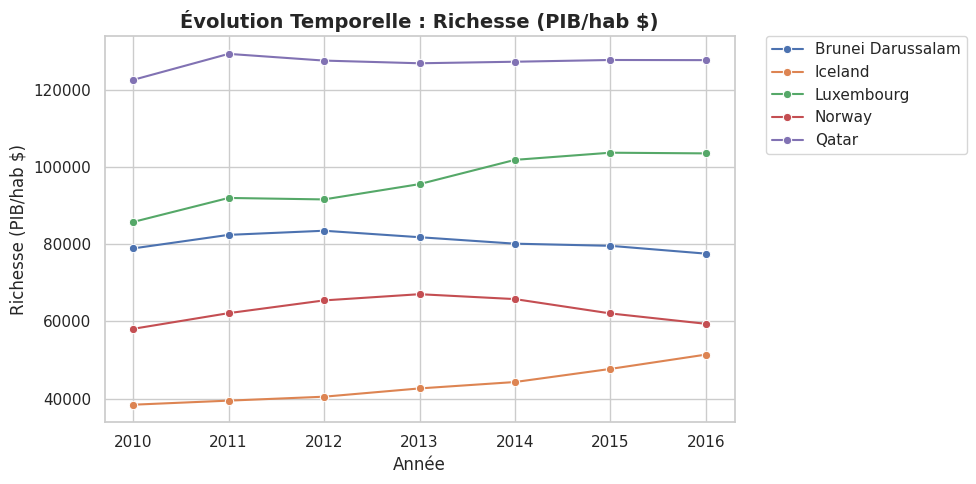

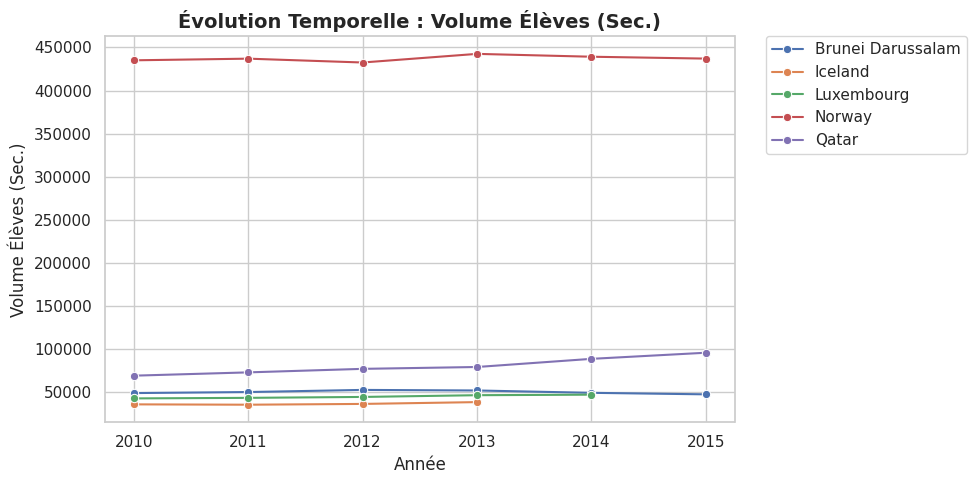

Étape 2 : Courbes d'évolution générées


In [13]:
## Étape 2 : Analyse de l'Évolution (Tendances)

def plot_evolution(df, indicators):
    """Trace l'évolution temporelle des indicateurs pour le Top 5."""

    # On reprend le melt (format long)
    years = [str(y) for y in range(CONFIG["YEAR_RANGE"][0], CONFIG["YEAR_RANGE"][1] + 1)
             if str(y) in df.columns]

    df_melt = df.melt(id_vars=['Country Name', 'Indicator Code'],
                      value_vars=years,
                      var_name='Year',
                      value_name='Value')

    # Conversion de l'année en numérique pour le tracé
    df_melt['Year'] = pd.to_numeric(df_melt['Year'])

    # On se limite au Top 5 pour la lisibilité
    top_5_names = df_final.head(5).index.get_level_values('Country Name')
    df_melt_top5 = df_melt[df_melt['Country Name'].isin(top_5_names)]

    for ind in indicators:
        # Récupération du nom français
        titre_fr = CONFIG["LABELS"].get(ind, ind)

        plt.figure(figsize=(10, 5))

        subset = df_melt_top5[df_melt_top5['Indicator Code'] == ind]

        sns.lineplot(data=subset, x="Year", y="Value", hue="Country Name", marker="o")

        plt.title(f"Évolution Temporelle : {titre_fr}", fontsize=14, fontweight='bold')
        plt.ylabel(titre_fr)
        plt.xlabel("Année")
        plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_evolution(df_top_evolution, CONFIG["INDICATORS"])
print("Étape 2 : Courbes d'évolution générées")

#Étape 3 : Analyse des Corrélations (Heatmap)

**Explication :**

Existe-t-il un lien entre la richesse (PIB) et l'accès à Internet ? Ou entre la population jeune et la scolarisation ?

La matrice de corrélation de Pearson nous permet de vérifier la cohérence des données.

Une corrélation proche de 1 signifie que les indicateurs évoluent ensemble.

Une corrélation proche de -1 signifie qu'ils évoluent en sens inverse.

**Note :** On calcule la corrélation sur le dataset df_pivot (celui qui a une colonne par indicateur).

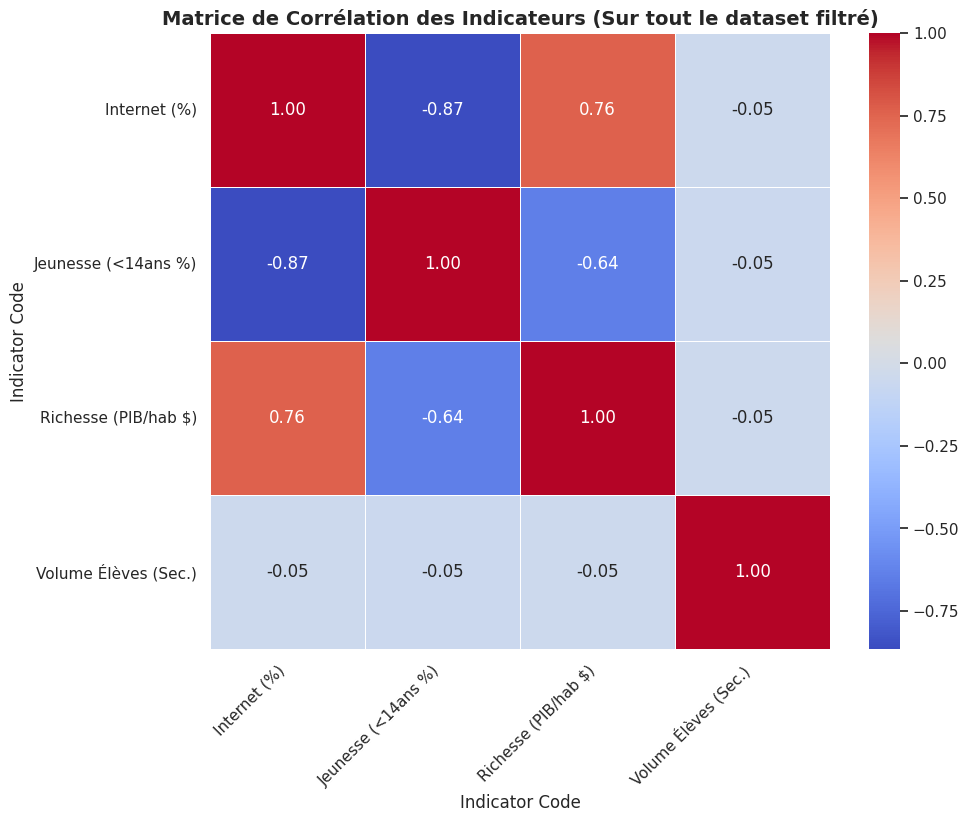

Étape 3 : Analyse des corrélations terminée.


In [14]:
## Étape 3 : Matrice de Corrélation

def plot_correlation(df):
    plt.figure(figsize=(10, 8))

    # On ne garde que les colonnes indicateurs
    # (Attention : df contient aussi les colonnes _norm, on prend les brutes)
    cols_to_corr = CONFIG["INDICATORS"]

    # Création d'un sous-ensemble avec les noms traduits en Français
    df_corr = df[cols_to_corr].rename(columns=CONFIG["LABELS"])

    # Calcul
    corr_matrix = df_corr.corr()

    # Heatmap
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

    plt.title("Matrice de Corrélation des Indicateurs (Sur tout le dataset filtré)", fontsize=14, fontweight='bold')

    # Rotation des labels pour qu'ils soient lisibles
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()

# On utilise df_pivot (celui de l'Ex 1 qui contient tous les pays valides)
plot_correlation(df_pivot)
print("Étape 3 : Analyse des corrélations terminée.")

#Résultats & Interprétation

**Explication :**

Le Data Analyst ne se contente pas de montrer des graphiques, il conclut.
Cette cellule génère un résumé textuel automatique basé sur les données.

In [15]:
print(" --- SYNTHÈSE DE L'ANALYSE (Note pour Mark) ---")

# Récupération du Top 1 (Nom et Score)
# df_final.index est un MultiIndex (Nom, Code), on prend le premier élément
top_country_name = df_final.index[0][0]
score_top = df_final.iloc[0]['Total_Score']
internet_top = df_final.iloc[0]['IT.NET.USER.P2']

print(f"1. Le candidat idéal identifié est : {top_country_name} (Score: {score_top:.2f}).")
print(f"2. Point fort majeur : Taux de pénétration Internet de {internet_top:.1f}%.")

# Comparaison USA
if 'USA' in top_countries_codes:
    # On récupère les données USA
    usa_data = df_final.xs('USA', level='Country Code')

    # On extrait la valeur unique avec .iloc[0]
    vol_usa = usa_data['SE.SEC.ENRL'].iloc[0]

    print(f"3. Note Stratégique : Les USA sont classés mais offrent un volume (SE.SEC.ENRL) de {vol_usa:,.0f} élèves.")
    print("   -> Recommandation : Cibler les USA pour le volume, ou le Top 1 pour la facilité d'entrée.")

print(" Exercice 2 TERMINÉ")

 --- SYNTHÈSE DE L'ANALYSE (Note pour Mark) ---
1. Le candidat idéal identifié est : Luxembourg (Score: 0.49).
2. Point fort majeur : Taux de pénétration Internet de 93.7%.
3. Note Stratégique : Les USA sont classés mais offrent un volume (SE.SEC.ENRL) de 24,170,952 élèves.
   -> Recommandation : Cibler les USA pour le volume, ou le Top 1 pour la facilité d'entrée.
 Exercice 2 TERMINÉ


## **EXERCICE 3 :**

#Prédiction du Potentiel

Objectif : Estimer l'évolution de la pénétration d'Internet à l'horizon 2025/2030 pour valider la pérennité de l'investissement.

**Étape 1 :**

Préparation du Moteur de Prédiction

**Explication :**

Nous allons utiliser une Régression Linéaire simple (scikit-learn). Pourquoi ? Parce que sur des tendances macro-économiques courtes (10 ans), l'évolution est souvent linéaire ou logistique. Nous allons créer une fonction qui "apprend" la tendance passée de chaque pays pour prolonger la courbe.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

print("--- Démarrage de l'Exercice 3 : Forecasting ---")

# --- 1. DÉFINITION DU MOTEUR DE PRÉDICTION ---
def predict_trend(df_source, country_code, indicator, target_year=2025):
    """
    Entraîne un modèle linéaire sur l'historique et prédit le futur.
    Retourne : La prédiction et le score de fiabilité (R2).
    """
    # 1. Extraction des données pour ce pays et cet indicateur
    # On filtre sur le code pays et le code indicateur
    mask = (df_source['Country Code'] == country_code) & (df_source['Indicator Code'] == indicator)
    data = df_source[mask].copy()

    # 2. Nettoyage et formatage (Melt)
    # On ne garde que les colonnes numériques (les années)
    years_cols = [c for c in data.columns if c.isdigit()]

    if not years_cols:
        return None, 0 # Pas de colonnes années trouvées

    df_ts = data.melt(value_vars=years_cols, var_name='Year', value_name='Value')
    df_ts['Year'] = pd.to_numeric(df_ts['Year'])
    df_ts = df_ts.dropna().sort_values('Year')

    # 3. Vérification : A-t-on assez de points pour une régression ? (Min 3 points)
    if len(df_ts) < 3:
        return None, 0

    # 4. Entraînement (X doit être en 2D pour scikit-learn)
    X = df_ts[['Year']].values
    y = df_ts['Value'].values

    model = LinearRegression()
    model.fit(X, y)

    # Calcul du score R2 (Fiabilité de la ligne)
    score_r2 = model.score(X, y)

    # 5. Prédiction
    future_X = np.array([[target_year]])
    prediction = model.predict(future_X)[0]

    # Capping (Si c'est un %, on ne peut pas dépasser 100%)
    if "USER.P2" in indicator or "ZS" in indicator:
        prediction = min(prediction, 100.0)
        prediction = max(prediction, 0.0)

    return prediction, score_r2, df_ts # On retourne aussi l'historique pour le plot

--- Démarrage de l'Exercice 3 : Forecasting ---


#Étape 2 : Projection des "Champions" (Top 5)

**Explication :**

Nous appliquons le modèle sur notre Top 5 identifié à l'Exercice 1. Nous allons comparer leur taux d'Internet actuel (2015-2020) avec la projection 2025.

Analyse prédictive pour l'indicateur : IT.NET.USER.P2


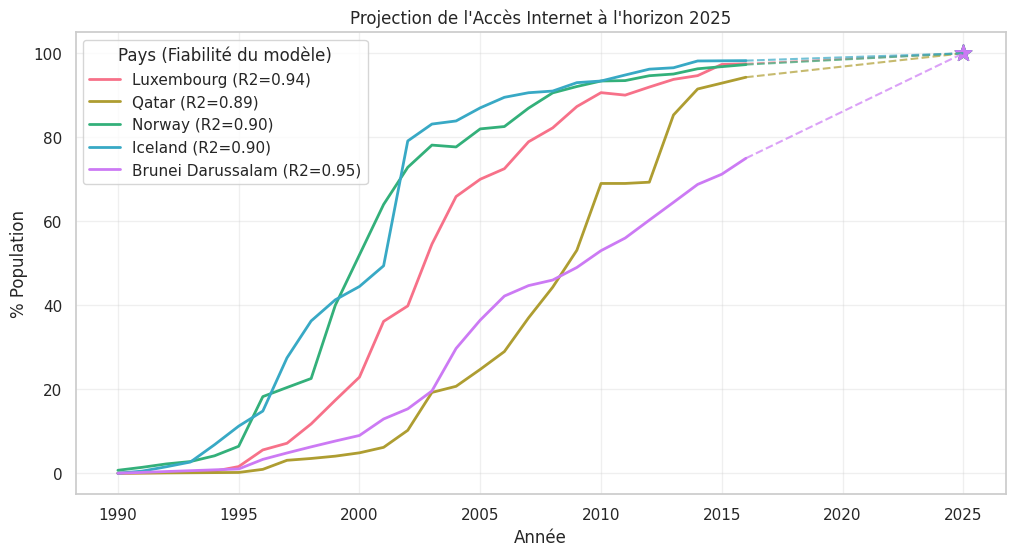

In [17]:
# --- 2. APPLICATION SUR LE TOP 5 ---

target_ind = 'IT.NET.USER.P2' # Indicateur Internet
future_year = 2025
forecast_results = []

print(f"Analyse prédictive pour l'indicateur : {target_ind}")

# On reprend le Top 5 issu de l'étape précédente (df_final)
# df_final.index est un MultiIndex (Country Name, Country Code)
top_5_countries = df_final.head(5).index

plt.figure(figsize=(12, 6))
colors = sns.color_palette("husl", 5) # Palette de couleurs distinctes

for i, (country_name, country_code) in enumerate(top_5_countries):

    # Appel de la fonction (sur df_data qui contient tout l'historique brut)
    # Note: On utilise df_data car df_clean a été filtré sur les années réduites
    pred, r2, history = predict_trend(df_data, country_code, target_ind, future_year)

    if pred is not None:
        # Stockage résultat
        current_val = history['Value'].iloc[-1]
        last_year = history['Year'].iloc[-1]

        forecast_results.append({
            "Pays": country_name,
            "Dernier Connu": current_val,
            f"Prédiction {future_year}": pred,
            "Confiance (R2)": r2
        })

        # --- TRACÉ GRAPHIQUE ---
        # 1. Historique (Ligne pleine)
        plt.plot(history['Year'], history['Value'], label=f"{country_name} (R2={r2:.2f})", color=colors[i], linewidth=2)

        # 2. Futur (Pointillés)
        plt.plot([last_year, future_year], [current_val, pred], linestyle='--', color=colors[i], alpha=0.7)

        # 3. Point final (Étoile)
        plt.scatter(future_year, pred, color=colors[i], marker='*', s=150)

plt.title(f"Projection de l'Accès Internet à l'horizon {future_year}")
plt.xlabel("Année")
plt.ylabel("% Population")
plt.legend(title="Pays (Fiabilité du modèle)", loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

#Étape 3 : Visualisation "Passé vs Futur"

**Explication :**

Nous allons tracer les lignes historiques en trait plein et la projection future en pointillés afin de voir se désciner un probable futur de progression.

In [18]:
# --- 3. TABLEAU RÉCAPITULATIF ---
df_forecast = pd.DataFrame(forecast_results)
print("\n--- RÉSULTATS DES PRÉDICTIONS ---")
# Affichage formaté
print(df_forecast.to_string(formatters={
    'Dernier Connu': '{:,.1f}%'.format,
    f'Prédiction {future_year}': '{:,.1f}%'.format,
    'Confiance (R2)': '{:,.2f}'.format
}))


--- RÉSULTATS DES PRÉDICTIONS ---
                Pays Dernier Connu Prédiction 2025 Confiance (R2)
0         Luxembourg         97.5%          100.0%           0.94
1              Qatar         94.3%          100.0%           0.89
2             Norway         97.3%          100.0%           0.90
3            Iceland         98.2%          100.0%           0.90
4  Brunei Darussalam         75.0%          100.0%           0.95


#Conclusion Générale du Projet

In [19]:
print(f"\n{'='*10} SYNTHÈSE STRATÉGIQUE & RECOMMANDATIONS {'='*10}")

# 1. Le gagnant du Scoring (Qualité / Test)
# On récupère le premier index (qui est un tuple si MultiIndex)
top_country_index = df_final.index[0]
# On gère l'affichage du nom proprement (si tuple, on prend le premier élément)
top_country_name = top_country_index[0] if isinstance(top_country_index, tuple) else top_country_index

top_country_score = df_final.iloc[0]['Total_Score']
top_country_internet = df_final.iloc[0]['IT.NET.USER.P2']

# 2. Le géant du volume (USA)
target_volume_country = "United States"

# On filtre intelligemment pour trouver la ligne, peu importe l'index
usa_row = df_final[df_final.index.get_level_values('Country Name') == target_volume_country]

print(f"\nSuite à l'analyse multidimensionnelle, voici deux axes stratégiques selon l'appétence au risque :\n")

# --- RECOMMANDATION 1 ---
print(f"1 CIBLE PILOTE (Qualité & Sécurité) : {top_country_name}")
print(f"   ------------------------------------------------")
print(f"   • Justification : Score maximal de {top_country_score:.2f}/1.0.")
print(f"   • Atouts : Infrastructure mature ({top_country_internet:.1f}% connectés) et fort pouvoir d'achat.")
print(f"   • Stratégie : Idéal pour un 'Soft Launch' (Beta-test) à faible risque.")

# --- RECOMMANDATION 2 ---
if not usa_row.empty:
    # CORRECTION ICI : On utilise .values[0] pour extraire la valeur brute (le scalaire)
    usa_score = usa_row['Total_Score'].values[0]
    usa_students = usa_row['SE.SEC.ENRL'].values[0]

    # On recalcule le rang dynamiquement
    usa_rank = df_final.index.get_loc(usa_row.index[0]) + 1

    print(f"2 CIBLE EXPANSION (Volume & Rentabilité) : {target_volume_country}")
    print(f"   ------------------------------------------------")
    print(f"   • Position : {usa_rank}ème au classement général (Score : {usa_score:.2f}).")
    print(f"   • Le Paradoxe Stratégique : Moins bien noté que le {top_country_name} sur la moyenne,")
    print(f"     mais dispose d'un vivier massif de {usa_students:,.0f} élèves dans le secondaire.")
    print(f"   • Potentiel : Le volume compense largement le score légèrement inférieur.")
    print(f"   • Stratégie : Cible prioritaire pour la phase de croissance (Scale-up).")

print(f"\n{'='*45}")

print("That's All Folcks !!! ")


========== SYNTHÈSE STRATÉGIQUE & RECOMMANDATIONS ==========

Suite à l'analyse multidimensionnelle, voici deux axes stratégiques selon l'appétence au risque :

1 CIBLE PILOTE (Qualité & Sécurité) : Luxembourg
   ------------------------------------------------
   • Justification : Score maximal de 0.49/1.0.
   • Atouts : Infrastructure mature (93.7% connectés) et fort pouvoir d'achat.
   • Stratégie : Idéal pour un 'Soft Launch' (Beta-test) à faible risque.
2 CIBLE EXPANSION (Volume & Rentabilité) : United States
   ------------------------------------------------
   • Position : 7ème au classement général (Score : 0.41).
   • Le Paradoxe Stratégique : Moins bien noté que le Luxembourg sur la moyenne,
     mais dispose d'un vivier massif de 24,170,952 élèves dans le secondaire.
   • Potentiel : Le volume compense largement le score légèrement inférieur.
   • Stratégie : Cible prioritaire pour la phase de croissance (Scale-up).

That's All Folcks !!! 
